In [ ]:
import os
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Гречишкин Денис, ПМ-41
## Лабораторная работа №5
## Нейронные сети

## Цель работы:  знакомство с графовыми нейронными сетями и типовыми задачи их приложения, а также сравнение производительности и качества работы графовых сетей с неспециализированными нейросетевыми моделями.

# Часть 1. Классификация вершин графов с помощью графовых сетей

## 1.1. Подготовка к работе.

In [ ]:
zip_file = keras.utils.get_file(
  fname="cora.tgz",
  origin="https://linqs-data.soe.ucsc.edu/public/lbc/cora.tgz",
  extract=True,
)
data_dir = os.path.join(os.path.dirname(zip_file), "cora_extracted/cora")
print(data_dir)

citations = pd.read_csv(
  os.path.join(data_dir, "cora.cites"),
  sep="\t",
  header=None,
  names=["target", "source"],
)
print("Citations shape:", citations.shape)

citations.sample(frac=1).head()



168052/168052 ━━━━━━━━━━━━━━━━━━━━ 1s 3us/step
/root/.keras/datasets/cora_extracted/cora
Citations shape: (5429, 2)


,target,source
190,114,28287
1587,8699,104840
5232,644427,644577
549,1997,1109542
1277,6213,58540


In [ ]:
column_names = ["paper_id"] + [f"term_{idx}" for idx in range(1433)] + ["subject"]
papers = pd.read_csv(
  os.path.join(data_dir, "cora.content"), sep="\t", header=None,
  names=column_names,
)
print("Papers shape:", papers.shape)


Papers shape: (2708, 1435)


In [ ]:
print(papers.sample(5).T)

                            347            1528    1661  \
paper_id                    3187          66782  219239   
term_0                         0              0       0   
term_1                         0              0       0   
term_2                         0              0       0   
term_3                         0              0       0   
...                          ...            ...     ...   
term_1429                      0              0       0   
term_1430                      0              0       0   
term_1431                      0              0       0   
term_1432                      0              0       0   
subject    Probabilistic_Methods  Rule_Learning  Theory   

                            2114                546   
paper_id                  684972             1137466  
term_0                         0                   0  
term_1                         0                   0  
term_2                         0                   0  
term_3          

In [ ]:
print(papers.subject.value_counts())

subject
Neural_Networks           818
Probabilistic_Methods     426
Genetic_Algorithms        418
Theory                    351
Case_Based                298
Reinforcement_Learning    217
Rule_Learning             180
Name: count, dtype: int64


In [ ]:
class_values = sorted(papers["subject"].unique())
class_idx = {name: id for id, name in enumerate(class_values)}
paper_idx = {name: idx for idx, name in enumerate(sorted(papers["paper_id"].unique()))}
papers["paper_id"] = papers["paper_id"].apply(lambda name: paper_idx[name])
citations["source"] = citations["source"].apply(lambda name: paper_idx[name])
citations["target"] = citations["target"].apply(lambda name: paper_idx[name])
papers["subject"] = papers["subject"].apply(lambda value: class_idx[value])

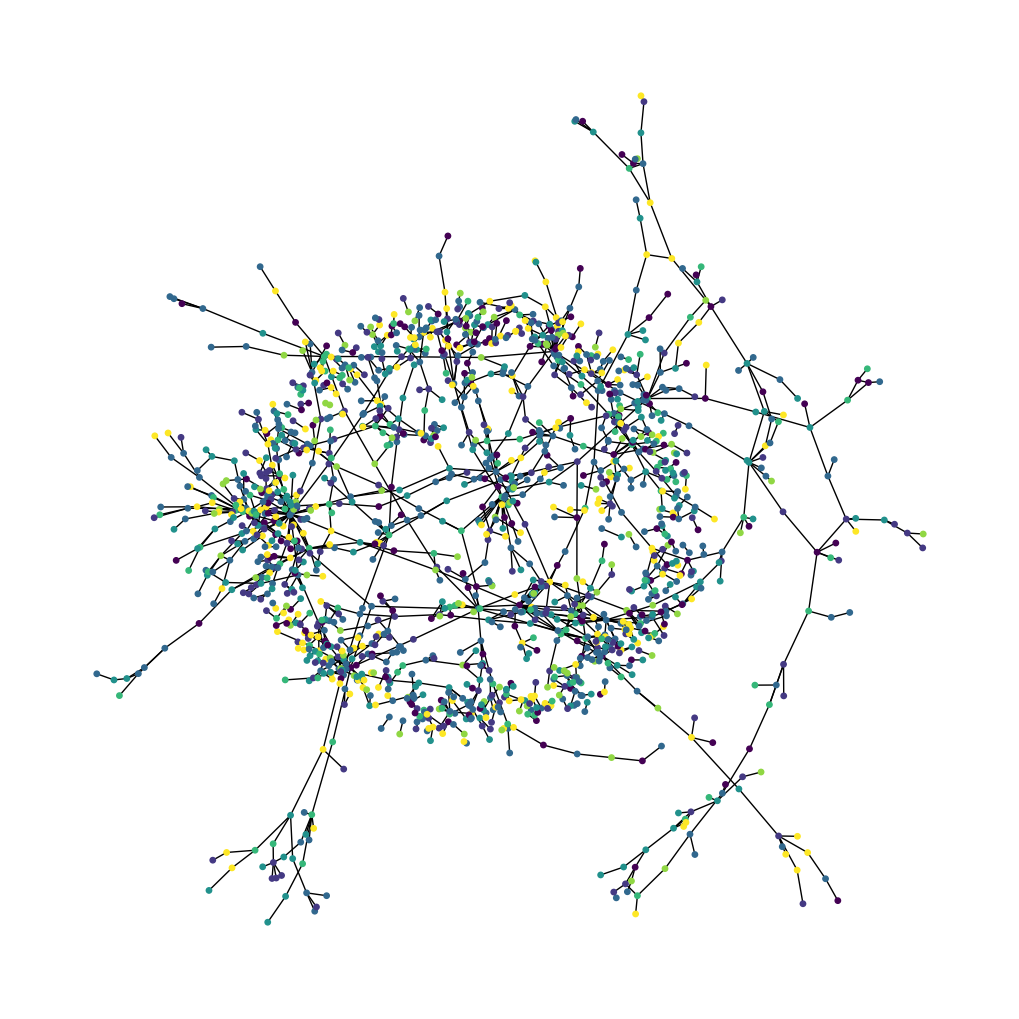

In [ ]:
plt.figure(figsize=(10, 10))
colors = papers["subject"].tolist()
cora_graph = nx.from_pandas_edgelist(citations.sample(n=1500))
subjects = list(papers[papers["paper_id"].isin(list(cora_graph.nodes))]["subject"])
nx.draw_spring(cora_graph, node_size=15, node_color=subjects)

In [ ]:
train_data, test_data = [], []
for _, group_data in papers.groupby("subject"):
  # Выберем 50% всех примеров для обучения.
  random_selection = np.random.rand(len(group_data.index)) <= 0.5
  train_data.append(group_data[random_selection])
  test_data.append(group_data[~random_selection])
train_data = pd.concat(train_data).sample(frac=1)
test_data = pd.concat(test_data).sample(frac=1)
print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)


Train data shape: (1327, 1435)
Test data shape: (1381, 1435)


## 1.2. Подготовка к обучению.

In [ ]:
hidden_units = [32, 32]
learning_rate = 0.01
dropout_rate = 0.5
num_epochs = 300
batch_size = 256

def run_experiment(model, x_train, y_train):
  # Будем использовать метод Adam во всех моделях для начала
  model.compile(
    optimizer=keras.optimizers.Adam(learning_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")],
  )
  # Предусмотрим раннюю остановку в моделях.
  early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_acc", patience=50, restore_best_weights=True
  )
  # Fit the model.
  history = model.fit(
    x=x_train,
    y=y_train,
    epochs=num_epochs,
    batch_size=batch_size,
    validation_split=0.15, # выделение на валидацию 15% примеров
    callbacks=[early_stopping],
  )
  return history

def display_learning_curves(history):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

  ax1.plot(history.history["loss"])
  ax1.plot(history.history["val_loss"])
  ax1.legend(["train", "test"], loc="upper right")
  ax1.set_xlabel("Epochs")
  ax1.set_ylabel("Loss")

  ax2.plot(history.history["acc"])
  ax2.plot(history.history["val_acc"])
  ax2.legend(["train", "test"], loc="upper right")
  ax2.set_xlabel("Epochs")
  ax2.set_ylabel("Accuracy")

  plt.grid(True)
  plt.show()


## 1.3  Референсная полносвязная модель для классифакации вершин графа.

In [ ]:
def create_ffn(hidden_units, dropout_rate, name=None):
  fnn_layers = []

  for units in hidden_units:
    fnn_layers.append(layers.BatchNormalization())
    fnn_layers.append(layers.Dropout(dropout_rate))
    fnn_layers.append(layers.Dense(units, activation=tf.nn.gelu))

  return keras.Sequential(fnn_layers, name=name)


feature_names = list(set(papers.columns) - {"paper_id", "subject"})
num_features = len(feature_names)
num_classes = len(class_idx)

# Create train and test features as a numpy array.
x_train = train_data[feature_names].to_numpy()
x_test = test_data[feature_names].to_numpy()

# Create train and test targets as a numpy array.
y_train = train_data["subject"]
y_test = test_data["subject"]

def create_baseline_model(hidden_units, num_classes, dropout_rate=0.5):
  inputs = layers.Input(shape=(num_features,), name="input_features")
  x = create_ffn(hidden_units, dropout_rate, name=f"ffn_block1")(inputs)

  for block_idx in range(4):
    # Create an FFN block.
    x1 = create_ffn(hidden_units, dropout_rate,
    name=f"ffn_block{block_idx + 2}")(x)

    # Add skip connection.
    x = layers.Add(name=f"skip_connection{block_idx + 2}")([x, x1])

  # Compute logits.
  logits = layers.Dense(num_classes, name="logits")(x)

  # Create the model.
  return keras.Model(inputs=inputs, outputs=logits, name="baseline")


baseline_model = create_baseline_model(hidden_units, num_classes, dropout_rate)
baseline_model.summary()


Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_features      │ (None, 1433)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ffn_block1          │ (None, 32)        │     52,804 │ input_features[0… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ffn_block2          │ (None, 32)        │      2,368 │ ffn_block1[0][0]  │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_connection2    │ (None, 32)        │          0 │ ffn_block1[0][0], │
│ (Add)               │                   │            │ ffn_block2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ffn_block3          │ (None, 32)        │      2,368 │ skip_connection2… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_connection3    │ (None, 32)        │          0 │ skip_connection2… │
│ (Add)               │                   │            │ ffn_block3[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ffn_block4          │ (None, 32)        │      2,368 │ skip_connection3… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_connection4    │ (None, 32)        │          0 │ skip_connection3… │
│ (Add)               │                   │            │ ffn_block4[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ffn_block5          │ (None, 32)        │      2,368 │ skip_connection4… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_connection5    │ (None, 32)        │          0 │ skip_connection4… │
│ (Add)               │                   │            │ ffn_block5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, 7)         │        231 │ skip_connection5… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 62,507 (244.17 KB)

 Trainable params: 59,065 (230.72 KB)

 Non-trainable params: 3,442 (13.45 KB)

Epoch 1/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 121ms/step - acc: 0.1491 - loss: 3.6020 - val_acc: 0.2800 - val_loss: 1.8834
Epoch 2/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - acc: 0.2555 - loss: 2.8255 - val_acc: 0.3100 - val_loss: 1.8397
Epoch 3/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - acc: 0.2573 - loss: 2.4359 - val_acc: 0.3100 - val_loss: 1.8430
Epoch 4/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - acc: 0.2626 - loss: 2.0695 - val_acc: 0.3100 - val_loss: 1.8389
Epoch 5/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - acc: 0.2777 - loss: 2.0411 - val_acc: 0.3350 - val_loss: 1.8367
Epoch 6/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - acc: 0.2919 - loss: 1.9016 - val_acc: 0.3300 - val_loss: 1.8142
Epoch 7/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - acc: 0.3230 - loss: 1.8425 - val_acc: 0.3100 - val_loss: 1.7804
Epoch 8/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - acc: 0.3602 - loss: 1.7649 - val_acc: 0.3100 - val_loss: 1.7540
Epoch 9/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - acc: 0.3656 - loss:

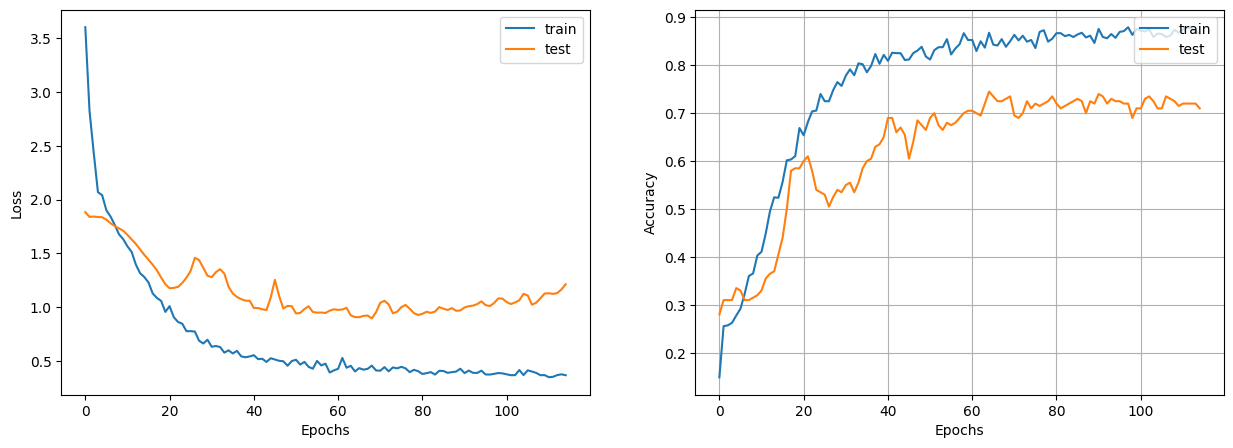

Test accuracy: 72.34%


In [ ]:
history = run_experiment(baseline_model, x_train, y_train)
display_learning_curves(history)
_, test_accuracy = baseline_model.evaluate(x=x_test, y=y_test, verbose=0)
print(f"Test accuracy: {round(test_accuracy * 100, 2)}%")

## 1.4. Построение графовой нейронной сети

In [ ]:
# Список ребер для цитирований (размер [2, num_edges]).
edges = citations[["source", "target"]].to_numpy().T

# Веса в нашей модели отсутсвуют, поэтому зададим их единицами.
edge_weights = tf.ones(shape=edges.shape[1])

# Создадим список для вершин и их признаков [num_nodes, num_features].
node_features = tf.cast(
  papers.sort_values("paper_id")[feature_names].to_numpy(),
  dtype=tf.dtypes.float32
)

# Итоговая структура для описания графа/подграфа в нашей модели
graph_info = (node_features, edges, edge_weights)

print("Edges shape:", edges.shape)
print("Nodes shape:", node_features.shape)


Edges shape: (2, 5429)
Nodes shape: (2708, 1433)


In [ ]:
def create_gru(hidden_units, dropout_rate):
  inputs = keras.layers.Input(shape=(2, hidden_units[0]))
  x = inputs

  for units in hidden_units:
    x = layers.GRU(
      units=units,
      activation="tanh",
      recurrent_activation="sigmoid",
      return_sequences=True,
      dropout=dropout_rate,
      return_state=False,
      recurrent_dropout=dropout_rate,
    )(x)

  return keras.Model(inputs=inputs, outputs=x)


class GraphConvLayer(layers.Layer):
  def __init__(self, hidden_units, dropout_rate=0.2, aggregation_type="mean", combination_type="concat", normalize=False, *args, **kwargs,):
    super().__init__(*args, **kwargs)
    self.aggregation_type = aggregation_type
    self.combination_type = combination_type
    self.normalize = normalize
    self.ffn_prepare = create_ffn(hidden_units, dropout_rate)
    if self.combination_type == "gru":
      self.update_fn = create_gru(hidden_units, dropout_rate)
    else:
      self.update_fn = create_ffn(hidden_units, dropout_rate)


  def prepare(self, node_repesentations, weights=None):
    # node_repesentations имеет размер [num_edges, embedding_dim].
    messages = self.ffn_prepare(node_repesentations)

    if weights is not None:
      messages = messages * tf.expand_dims(weights, -1)

    return messages

  def aggregate(self, node_indices, neighbour_messages, node_repesentations):
    # node_indices имеет размер [num_edges].
    # neighbour_messages имеет размер: [num_edges, representation_dim].
    # node_repesentations имеет размер [num_nodes, representation_dim].
    num_nodes = node_repesentations.shape[0]

    if self.aggregation_type == "sum":
      aggregated_message = tf.math.unsorted_segment_sum(
      neighbour_messages, node_indices, num_segments=num_nodes
      )

    elif self.aggregation_type == "mean":
      aggregated_message = tf.math.unsorted_segment_mean(
      neighbour_messages, node_indices, num_segments=num_nodes
      )

    elif self.aggregation_type == "max":
      aggregated_message = tf.math.unsorted_segment_max(
      neighbour_messages, node_indices, num_segments=num_nodes
      )

    else:
      raise ValueError(f"Invalid aggregation type:{self.aggregation_type}.")

    return aggregated_message

  def update(self, node_repesentations, aggregated_messages):
    # node_repesentations имеет размер [num_nodes, representation_dim].
    # aggregated_messages имеет размер [num_nodes, representation_dim].
    if self.combination_type == "gru":
      # Создаем последовательность для слоя GRU
      h = tf.stack([node_repesentations, aggregated_messages], axis=1)

    elif self.combination_type == "concat":
      h = tf.concat([node_repesentations, aggregated_messages], axis=1)

    elif self.combination_type == "add":
      h = node_repesentations + aggregated_messages

    else:
      raise ValueError(f"Invalid combination type:{self.combination_type}.")

    # Применяем на выбор GRU или FFN
    node_embeddings = self.update_fn(h)

    if self.combination_type == "gru":
      node_embeddings = tf.unstack(node_embeddings, axis=1)[-1]

    if self.normalize:
      node_embeddings = tf.nn.l2_normalize(node_embeddings, axis=-1)

    return node_embeddings

  def call(self, inputs):
    """
    Обработка входных данных для получения вложения node_embeddings.
    inputs: тройки вида: node_repesentations, edges, edge_weights.
    Returns: node_embeddings размера [num_nodes, representation_dim].
    """
    node_repesentations, edges, edge_weights = inputs

    # node_indices (source) и neighbour_indices (target) из ребер.
    node_indices, neighbour_indices = edges[0], edges[1]

    # neighbour_repesentations размера [num_edges, representation_dim].
    neighbour_repesentations = tf.gather(node_repesentations, neighbour_indices)

    # Подготовим данные для аггрегации на основе информации об окружении
    neighbour_messages = self.prepare( neighbour_repesentations, edge_weights)

    # Проведем аггрегацию в соответсвии с выбранным алгоритмом.
    aggregated_messages = self.aggregate(node_indices,
                                         neighbour_messages,
                                         node_repesentations)

    # Обновим информацию о вложении вершин
    return self.update(node_repesentations, aggregated_messages)


In [ ]:
class GNNNodeClassifier(tf.keras.Model):
  def __init__(self, graph_info, num_classes, hidden_units, aggregation_type="sum", combination_type="concat", dropout_rate=0.2, normalize=True, *args, **kwargs,):
    super().__init__(*args, **kwargs)
    node_features, edges, edge_weights = graph_info
    self.node_features = node_features
    self.edges = edges
    self.edge_weights = edge_weights

    # Set edge_weights to ones if not provided.
    if self.edge_weights is None:
      self.edge_weights = tf.ones(shape=edges.shape[1])

    # Scale edge_weights to sum to 1.
    self.edge_weights = self.edge_weights / tf.math.reduce_sum(self.edge_weights)

    # Слой для предобработки
    self.preprocess = create_ffn(hidden_units,
      dropout_rate, name="preprocess")

    # Первый сверточный слой
    self.conv1 = GraphConvLayer(
      hidden_units,
      dropout_rate,
      aggregation_type,
      combination_type,
      normalize,
      name="graph_conv1",
    )

    # Второй сверточный слой
    self.conv2 = GraphConvLayer(
      hidden_units,
      dropout_rate,
      aggregation_type,
      combination_type,
      normalize,
      name="graph_conv2",
    )

    # Слой для постобработки
    self.postprocess = create_ffn(hidden_units,
    dropout_rate, name="postprocess")

    # Create a compute logits layer.
    self.compute_logits = layers.Dense(units=num_classes,
    name="logits")

  def call(self, input_node_indices):
    x = self.preprocess(self.node_features)
    x1 = self.conv1((x, self.edges, self.edge_weights))
    # Простейшая сквозная связь
    x = x1 + x
    x2 = self.conv2((x, self.edges, self.edge_weights))
    # Простейшая сквозная связь
    x = x2 + x
    x = self.postprocess(x)
    node_embeddings = tf.gather(x, input_node_indices)
    # Compute logits
    return self.compute_logits(node_embeddings)

In [ ]:
gnn_model = GNNNodeClassifier(
  graph_info=graph_info,
  num_classes=num_classes,
  hidden_units=hidden_units,
  dropout_rate=0.2,
  name="gnn_model",
)
print("GNN output shape:", gnn_model(input_node_indices=[1,10,100]))
gnn_model.summary()

GNN output shape: tf.Tensor(
[[-0.00197251  0.08052233 -0.05297567  0.11218545  0.02647975  0.10814701
  -0.10660299]
 [-0.00837325  0.04945294 -0.05624726  0.09113151 -0.00774106  0.03223843
  -0.0342218 ]
 [-0.08102956  0.0158846   0.03315751  0.08974694 -0.02511024  0.08703458
  -0.11949423]], shape=(3, 7), dtype=float32)


Model: "gnn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ preprocess (Sequential)         │ (2708, 32)             │        52,804 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ graph_conv1 (GraphConvLayer)    │ ?                      │         5,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ graph_conv2 (GraphConvLayer)    │ ?                      │         5,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ postprocess (Sequential)        │ (2708, 32)             │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (3, 7)                 │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,179 (262.42 KB)

 Trainable params: 63,481 (247.97 KB)

 Non-trainable params: 3,698 (14.45 KB)

## 1.5. Обучение и оценка качества модели.

Epoch 1/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 248ms/step - acc: 0.2822 - loss: 1.8537 - val_acc: 0.4250 - val_loss: 1.6640
Epoch 2/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - acc: 0.4277 - loss: 1.5544 - val_acc: 0.4750 - val_loss: 1.4210
Epoch 3/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - acc: 0.5901 - loss: 1.1566 - val_acc: 0.6350 - val_loss: 1.1013
Epoch 4/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - acc: 0.7498 - loss: 0.6959 - val_acc: 0.6450 - val_loss: 1.2709
Epoch 5/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - acc: 0.8855 - loss: 0.3297 - val_acc: 0.7100 - val_loss: 1.1826
Epoch 6/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - acc: 0.9459 - loss: 0.1648 - val_acc: 0.6500 - val_loss: 1.6031
Epoch 7/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - acc: 0.9698 - loss: 0.0967 - val_acc: 0.6650 - val_loss: 1.7641
Epoch 8/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - acc: 0.9849 - loss: 0.0505 - val_acc: 0.6900 - val_loss: 1.6501
Epoch 9/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - acc: 0.9902 - loss

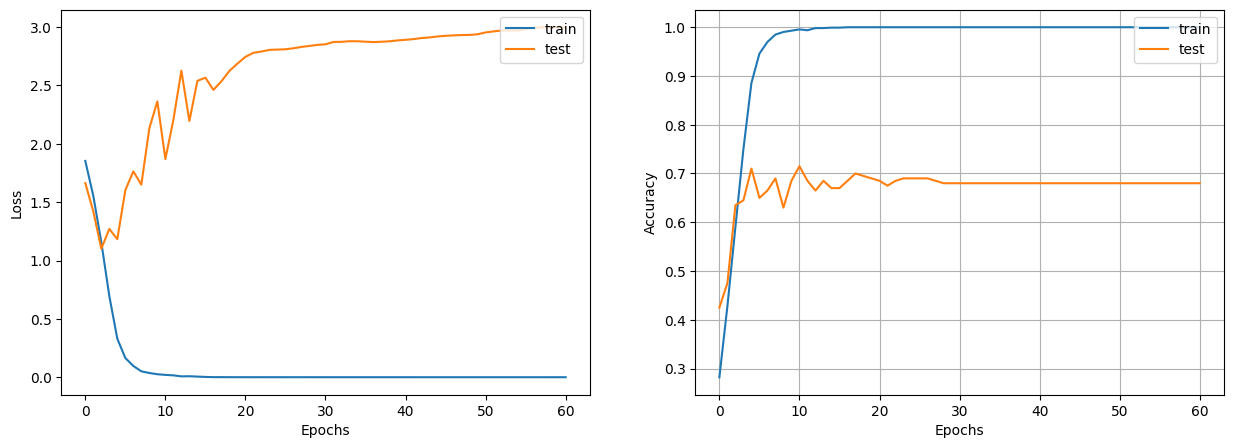

In [ ]:
x_train = train_data.paper_id.to_numpy()
history = run_experiment(gnn_model, x_train, y_train)
display_learning_curves(history)

# Часть 2. Предсказание свойств молекулярных графов

In [ ]:
!pip -q install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.0/37.0 MB 64.9 MB/s eta 0:00:00


In [ ]:
import os

# Temporary suppress tf logs
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from rdkit import Chem
from rdkit import RDLogger
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem.Draw import MolsToGridImage

# Temporary suppress warnings and RDKit logs
warnings.filterwarnings("ignore")
RDLogger.DisableLog("rdApp.*")
np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
csv_path = keras.utils.get_file("BBBP.csv", "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/BBBP.csv")
df = pd.read_csv(csv_path, usecols=[1, 2, 3])
df.iloc[96:104]

class Featurizer:
  def __init__(self, allowable_sets):
    self.dim = 0
    self.features_mapping = {}
    for k, s in allowable_sets.items():
      s = sorted(list(s))
      self.features_mapping[k] = dict(zip(s,range(self.dim,
      len(s) + self.dim)))
      self.dim += len(s)

  def encode(self, inputs):
    output = np.zeros((self.dim,))
    for name_feature, feature_mapping in self.features_mapping.items():
      feature = getattr(self, name_feature)(inputs)
      if feature not in feature_mapping:
        continue
      output[feature_mapping[feature]] = 1.0
    return output

class AtomFeaturizer(Featurizer):
  def __init__(self, allowable_sets):
    super().__init__(allowable_sets)
  def symbol(self, atom):
    return atom.GetSymbol()
  def n_valence(self, atom):
    return atom.GetTotalValence()
  def n_hydrogens(self, atom):
    return atom.GetTotalNumHs()
  def hybridization(self, atom):
    return atom.GetHybridization().name.lower()

class BondFeaturizer(Featurizer):
  def __init__(self, allowable_sets):
    super().__init__(allowable_sets)
    self.dim += 1

  def encode(self, bond):
    output = np.zeros((self.dim,))
    if bond is None:
      output[-1] = 1.0
      return output

    output = super().encode(bond)
    return output

  def bond_type(self, bond):
    return bond.GetBondType().name.lower()

  def conjugated(self, bond):
    return bond.GetIsConjugated()


atom_featurizer = AtomFeaturizer(
  allowable_sets={
    "symbol": {"B", "Br", "C", "Ca", "Cl", "F", "H", "I", "N",
    "Na", "O", "P", "S"},
    "n_valence": {0, 1, 2, 3, 4, 5, 6},
    "n_hydrogens": {0, 1, 2, 3, 4},
    "hybridization": {"s", "sp", "sp2", "sp3"},
  }
)

bond_featurizer = BondFeaturizer(
  allowable_sets={
  "bond_type": {"single", "double", "triple", "aromatic"},
  "conjugated": {True, False},
  }
)

148743/148743 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


In [ ]:
def molecule_from_smiles(smiles):
  molecule = Chem.MolFromSmiles(smiles, sanitize=False)

  # If sanitization is unsuccessful, catch the error, and try again
  # without the sanitization step that caused the error
  flag = Chem.SanitizeMol(molecule, catchErrors=True)
  if flag != Chem.SanitizeFlags.SANITIZE_NONE:
    Chem.SanitizeMol(molecule,
    sanitizeOps=Chem.SanitizeFlags.SANITIZE_ALL ^ flag)

  Chem.AssignStereochemistry(molecule, cleanIt=True, force=True)
  return molecule

def graph_from_molecule(molecule):
  # Initialize graph
  atom_features = []
  bond_features = []
  pair_indices = []
  for atom in molecule.GetAtoms():
    atom_features.append(atom_featurizer.encode(atom))
    # Add self-loops
    pair_indices.append([atom.GetIdx(), atom.GetIdx()])
    bond_features.append(bond_featurizer.encode(None))
    for neighbor in atom.GetNeighbors():
      bond = molecule.GetBondBetweenAtoms(atom.GetIdx(),
      neighbor.GetIdx())
      pair_indices.append([atom.GetIdx(), neighbor.GetIdx()])
      bond_features.append(bond_featurizer.encode(bond))

  return np.array(atom_features), np.array(bond_features), np.array(pair_indices)


def graphs_from_smiles(smiles_list):
  # Initialize graphs
  atom_features_list = []
  bond_features_list = []
  pair_indices_list = []
  for smiles in smiles_list:
    molecule = molecule_from_smiles(smiles)
    atom_features, bond_features, pair_indices = graph_from_molecule(molecule)

    atom_features_list.append(atom_features)
    bond_features_list.append(bond_features)
    pair_indices_list.append(pair_indices)
  return (
    tf.ragged.constant(atom_features_list, dtype=tf.float32),
    tf.ragged.constant(bond_features_list, dtype=tf.float32),
    tf.ragged.constant(pair_indices_list, dtype=tf.int64),
  )


Name:	acetylsalicylate
SMILES:	CC(=O)Oc1ccccc1C(O)=O 
BBBP:	0
Molecule:


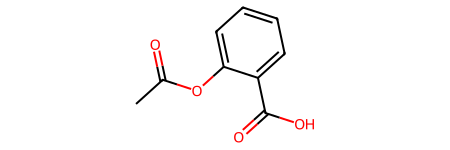

In [ ]:
# Shuffle array of indices ranging from 0 to 2049
permuted_indices = np.random.permutation(np.arange(df.shape[0]))

# Train set: 80 % of data
train_index = permuted_indices[: int(df.shape[0] * 0.8)]
x_train = graphs_from_smiles(df.iloc[train_index].smiles)
y_train = df.iloc[train_index].p_np

# Valid set: 19 % of data
valid_index = permuted_indices[int(df.shape[0] * 0.8) : int(df.shape[0] * 0.99)]
x_valid = graphs_from_smiles(df.iloc[valid_index].smiles)
y_valid = df.iloc[valid_index].p_np

# Test set: 1 % of data
test_index = permuted_indices[int(df.shape[0] * 0.99) :]
x_test = graphs_from_smiles(df.iloc[test_index].smiles)
y_test = df.iloc[test_index].p_np


#Проверим работу наших функций, визуализировав молекулярный граф.
print(f"Name:\t{df.name[100]}\nSMILES:\t{df.smiles[100]} \nBBBP:\t{df.p_np[100]}")
molecule = molecule_from_smiles(df.iloc[100].smiles)
print("Molecule:")
molecule


In [ ]:
graph = graph_from_molecule(molecule)
print("Graph (including self-loops):")
print("\tatom features\t", graph[0].shape)
print("\tbond features\t", graph[1].shape)
print("\tpair indices\t", graph[2].shape)


Graph (including self-loops):
	atom features	 (13, 29)
	bond features	 (39, 7)
	pair indices	 (39, 2)


In [ ]:
def prepare_batch(x_batch, y_batch):
  """Merges (sub)graphs of batch into a single global graph
  """
  atom_features, bond_features, pair_indices = x_batch

  # Obtain number of atoms and bonds for each graph (molecule)
  num_atoms = atom_features.row_lengths()
  num_bonds = bond_features.row_lengths()

  # Obtain partition indices (molecule_indicator), which will be used to
  # gather (sub)graphs from global graph in model later on
  molecule_indices = tf.range(len(num_atoms))
  molecule_indicator = tf.repeat(molecule_indices, num_atoms)

  # Merge (sub)graphs into a global (disconnected) graph.
  # Adding ’increment’ to ’pair_indices’ (and merging ragged tensors)
  # actualizes the global graph
  gather_indices = tf.repeat(molecule_indices[:-1], num_bonds[1:])
  increment = tf.cumsum(num_atoms[:-1])
  increment = tf.pad(tf.gather(increment, gather_indices), [(num_bonds[0], 0)])

  pair_indices = pair_indices.merge_dims(outer_axis=0, inner_axis=1).to_tensor()
  pair_indices = pair_indices + increment[:, tf.newaxis]

  atom_features = atom_features.merge_dims(outer_axis=0,inner_axis=1).to_tensor()
  bond_features = bond_features.merge_dims(outer_axis=0,inner_axis=1).to_tensor()

  return (atom_features,\
  bond_features,\
  pair_indices,\
  molecule_indicator),\
  y_batch

def MPNNDataset(X, y, batch_size=32, shuffle=False):
  dataset = tf.data.Dataset.from_tensor_slices((X, (y)))
  if shuffle:
    dataset = dataset.shuffle(1024)
  return dataset.batch(batch_size).map(prepare_batch, -1).prefetch(-1)



## 2.1. Реализация модели графовой нейронной сети.

In [ ]:
class EdgeNetwork(layers.Layer):
  def build(self, input_shape):
    self.atom_dim = input_shape[0][-1]
    self.bond_dim = input_shape[1][-1]
    self.kernel = self.add_weight(
      shape=(self.bond_dim, self.atom_dim * self.atom_dim),
      initializer="glorot_uniform",
      name="kernel",
    )
    self.bias = self.add_weight(
    shape=(self.atom_dim * self.atom_dim,),
    initializer="zeros",
    name="bias",
    )
    self.built = True

  def call(self, inputs):
    atom_features, bond_features, pair_indices = inputs

    # Apply linear transformation to bond features
    bond_features = tf.matmul(bond_features, self.kernel) + self.bias

    # Reshape for neighborhood aggregation later
    bond_features = tf.reshape(bond_features, (-1, self.atom_dim, self.atom_dim))

    # Obtain atom features of neighbors
    atom_features_neighbors = tf.gather(atom_features, pair_indices[:, 1])
    atom_features_neighbors = tf.expand_dims(atom_features_neighbors, axis=-1)

    # Apply neighborhood aggregation
    transformed_features = tf.matmul(bond_features,
    atom_features_neighbors)
    transformed_features = tf.squeeze(transformed_features, axis=-1)
    aggregated_features = tf.math.unsorted_segment_sum(
      transformed_features,
      pair_indices[:, 0],
      num_segments=tf.shape(atom_features)[0],
    )
    return aggregated_features


class MessagePassing(layers.Layer):
  def __init__(self, units, steps=4, **kwargs):
    super().__init__(**kwargs)
    self.units = units
    self.steps = steps
  def build(self, input_shape):
    self.atom_dim = input_shape[0][-1]
    self.message_step = EdgeNetwork()
    self.pad_length = max(0, self.units - self.atom_dim)
    self.update_step = layers.GRUCell(self.atom_dim + self.pad_length)
    self.built = True

  def call(self, inputs):
    atom_features, bond_features, pair_indices = inputs

    # Pad atom features if number of desired units
    # exceeds atom_features dim.
    atom_features_updated = tf.pad(atom_features, [(0, 0), (0,self.pad_length)])

    # Perform a number of steps of message passing
    for i in range(self.steps):

      # Aggregate information from neighbors
      atom_features_aggregated = self.message_step(
        [atom_features_updated, bond_features, pair_indices]
      )

      # Update node state via a step of GRU
      atom_features_updated, _ = self.update_step(
        atom_features_aggregated, atom_features_updated
      )
    return atom_features_updated


In [ ]:
class PartitionPadding(layers.Layer):
  def __init__(self, batch_size, **kwargs):
    super().__init__(**kwargs)
    self.batch_size = batch_size
  def call(self, inputs):
    atom_features, molecule_indicator = inputs

    # Obtain subgraphs
    atom_features_partitioned = tf.dynamic_partition(
    atom_features, molecule_indicator, self.batch_size
    )

    # Pad and stack subgraphs
    num_atoms = [tf.shape(f)[0] for f in atom_features_partitioned]
    max_num_atoms = tf.reduce_max(num_atoms)
    atom_features_stacked = tf.stack(
        [tf.pad(f, [(0, max_num_atoms - n), (0, 0)]) for f, n in zip(atom_features_partitioned, num_atoms)],
        axis=0,
    )

    # Remove empty subgraphs (usually for last batch in dataset)
    gather_indices = tf.where(tf.reduce_sum(atom_features_stacked,(1, 2)) != 0)
    gather_indices = tf.squeeze(gather_indices, axis=-1)

    return tf.gather(atom_features_stacked, gather_indices, axis=0)


class TransformerEncoderReadout(layers.Layer):
  def __init__(self, num_heads=8, embed_dim=64, dense_dim=512, batch_size=32, **kwargs):
    super().__init__(**kwargs)
    self.partition_padding = PartitionPadding(batch_size)
    self.attention = layers.MultiHeadAttention(num_heads, embed_dim)
    self.dense_proj = keras.Sequential(
    [layers.Dense(dense_dim, activation="relu"),
    layers.Dense(embed_dim),]
    )
    self.layernorm_1 = layers.LayerNormalization()
    self.layernorm_2 = layers.LayerNormalization()
    self.average_pooling = layers.GlobalAveragePooling1D()

  def call(self, inputs):
    x = self.partition_padding(inputs)
    padding_mask = tf.reduce_any(tf.not_equal(x, 0.0), axis=-1)
    padding_mask = padding_mask[:, tf.newaxis, tf.newaxis, :]
    attention_output = self.attention(x, x, attention_mask=padding_mask)
    proj_input = self.layernorm_1(x + attention_output)
    proj_output = self.layernorm_2(proj_input +
    self.dense_proj(proj_input))
    return self.average_pooling(proj_output)

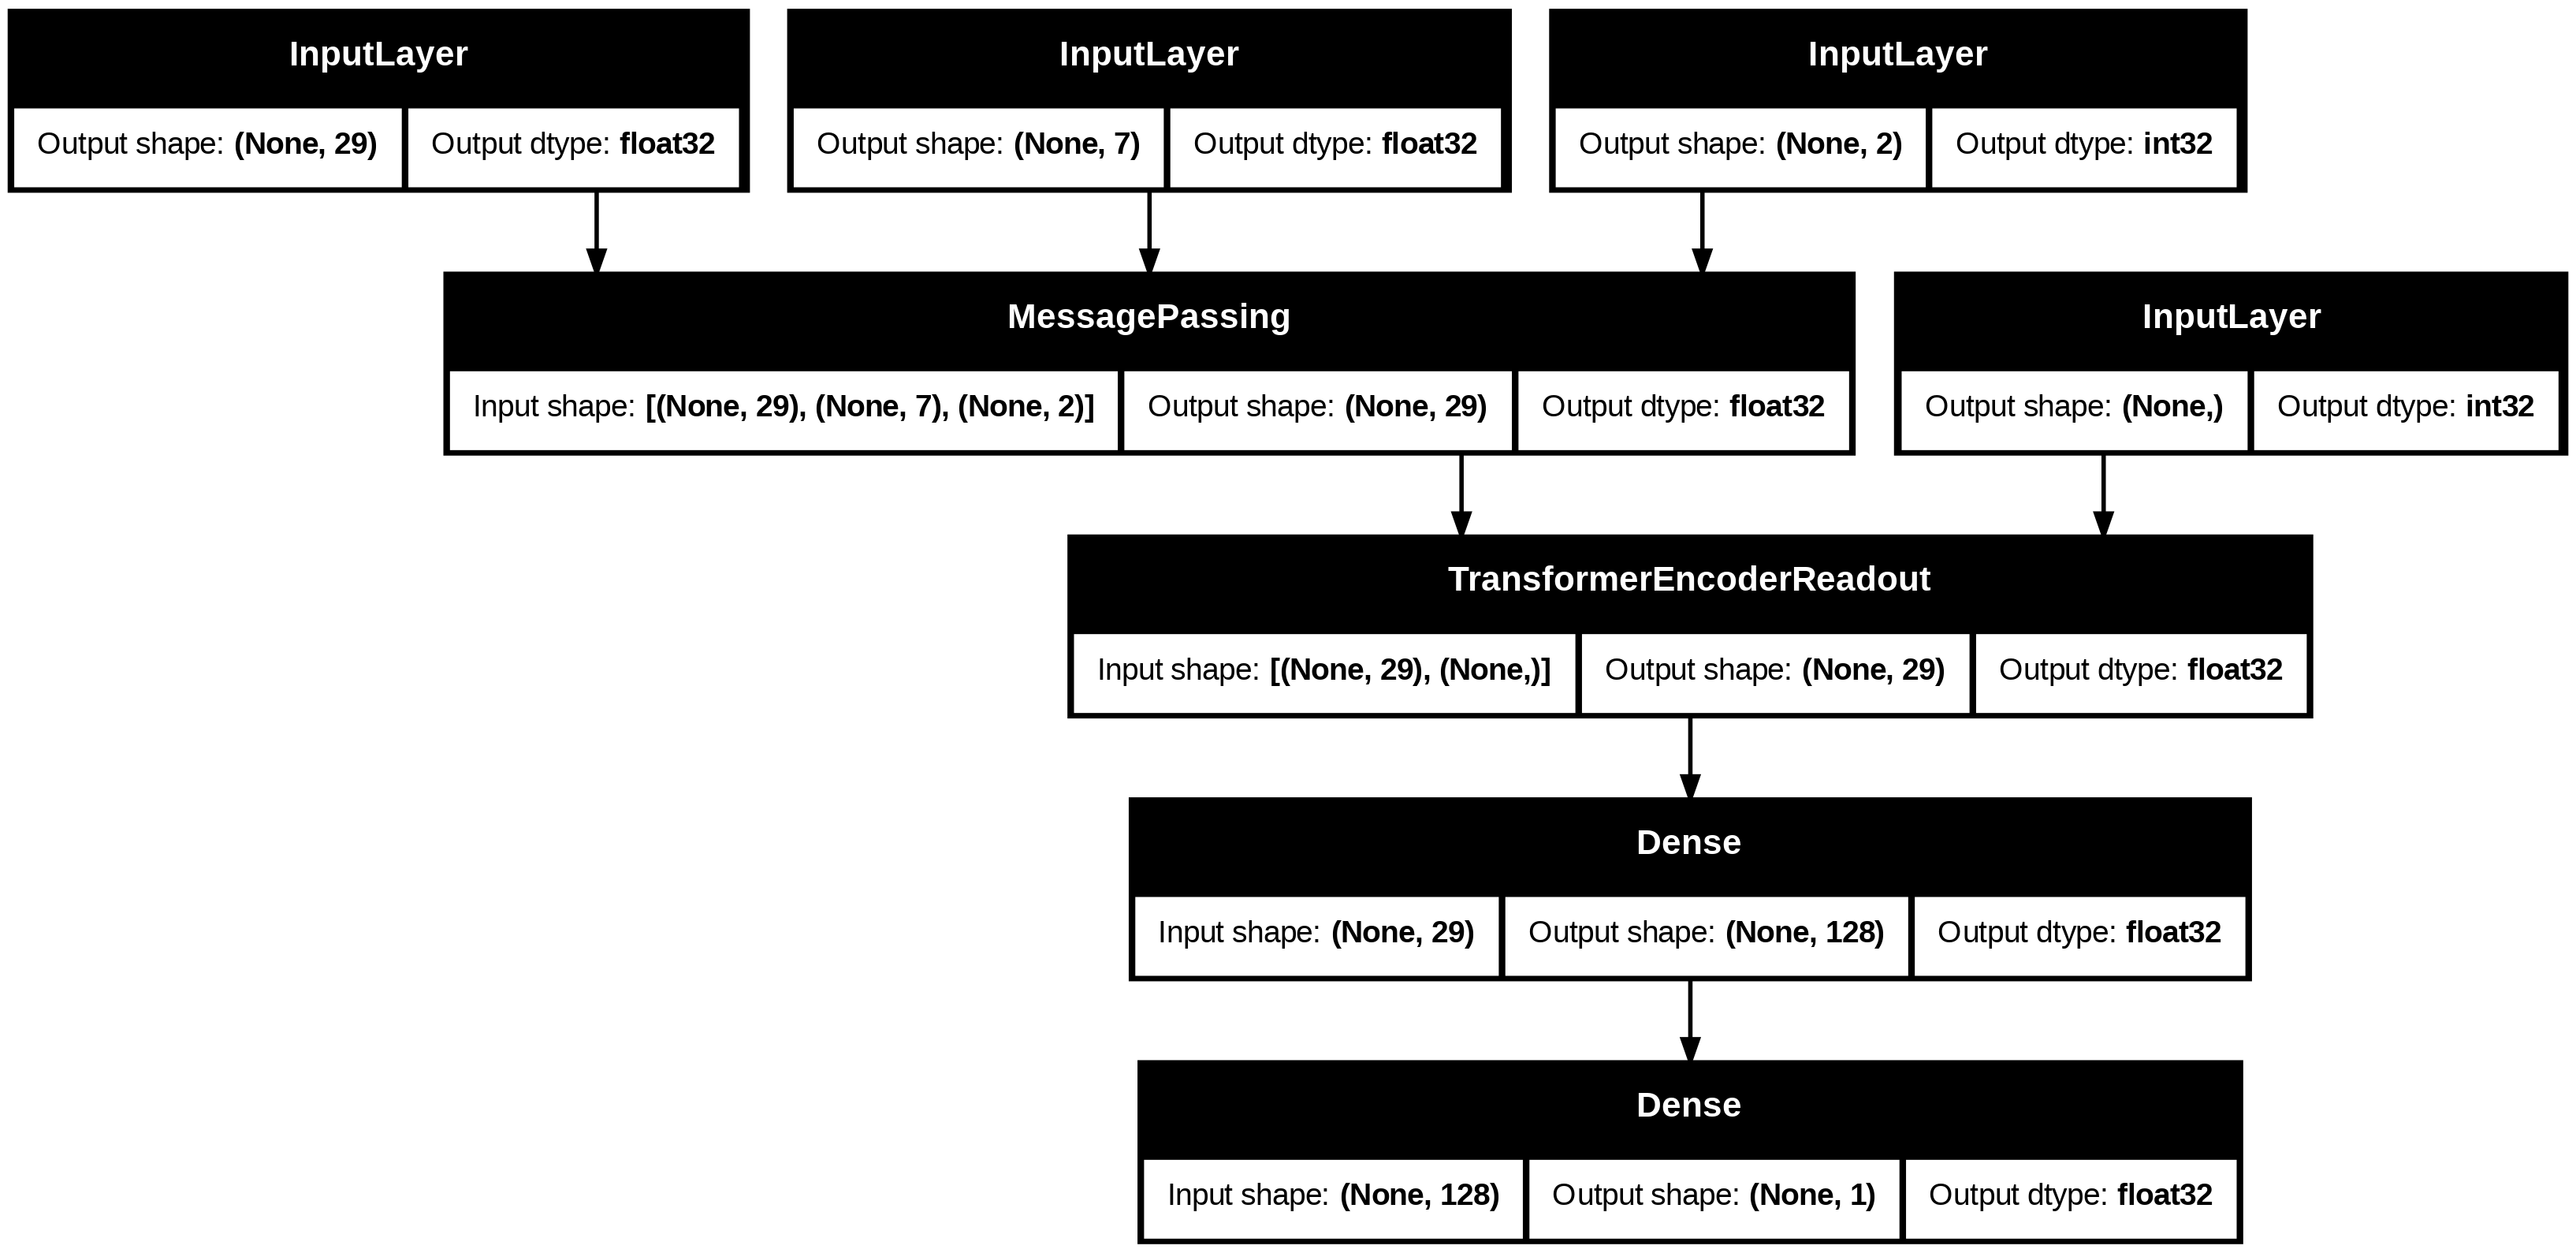

In [ ]:
def MPNNModel(atom_dim, bond_dim, batch_size=32, message_units=29, message_steps=4, num_attention_heads=8, dense_units=512,):
  atom_features = layers.Input((atom_dim,), dtype="float32", name="atom_features")
  bond_features = layers.Input((bond_dim,), dtype="float32", name="bond_features")
  pair_indices = layers.Input((2,), dtype="int32", name="pair_indices")
  molecule_indicator = layers.Input((), dtype="int32", name="molecule_indicator")

  x = MessagePassing(message_units, message_steps)([atom_features, bond_features, pair_indices])
  x = TransformerEncoderReadout(num_attention_heads, message_units, dense_units, batch_size)([x, molecule_indicator])
  x = layers.Dense(dense_units, activation="relu")(x)
  x = layers.Dense(1, activation="sigmoid")(x)

  model = keras.Model(
    inputs=[atom_features,
    bond_features,
    pair_indices,
    molecule_indicator],
    outputs=[x],
  )
  return model

mpnn = MPNNModel(
  atom_dim=x_train[0][0][0].shape[0], bond_dim=x_train[1][0][0].shape[0],
  dense_units = 128
)

mpnn.compile(
  loss=keras.losses.BinaryCrossentropy(),
  optimizer=keras.optimizers.Adam(learning_rate=5e-4),
  metrics=[keras.metrics.AUC(name="AUC")],
)
keras.utils.plot_model(mpnn, show_dtype=True, show_shapes=True)



Epoch 1/40
52/52 - 15s - 298ms/step - AUC: 0.7212 - loss: 0.5221 - val_AUC: 0.8385 - val_loss: 0.4885
Epoch 2/40
52/52 - 8s - 149ms/step - AUC: 0.7948 - loss: 0.4660 - val_AUC: 0.8528 - val_loss: 0.5719
Epoch 3/40
52/52 - 7s - 141ms/step - AUC: 0.8023 - loss: 0.4598 - val_AUC: 0.8562 - val_loss: 0.5336
Epoch 4/40
52/52 - 7s - 131ms/step - AUC: 0.8105 - loss: 0.4508 - val_AUC: 0.8570 - val_loss: 0.5422
Epoch 5/40
52/52 - 8s - 157ms/step - AUC: 0.8149 - loss: 0.4456 - val_AUC: 0.8592 - val_loss: 0.5121
Epoch 6/40
52/52 - 6s - 122ms/step - AUC: 0.8223 - loss: 0.4379 - val_AUC: 0.8620 - val_loss: 0.5085
Epoch 7/40
52/52 - 8s - 149ms/step - AUC: 0.8302 - loss: 0.4295 - val_AUC: 0.8607 - val_loss: 0.5000
Epoch 8/40
52/52 - 9s - 174ms/step - AUC: 0.8379 - loss: 0.4213 - val_AUC: 0.8644 - val_loss: 0.4903
Epoch 9/40
52/52 - 7s - 144ms/step - AUC: 0.8420 - loss: 0.4165 - val_AUC: 0.8679 - val_loss: 0.4988
Epoch 10/40
52/52 - 7s - 135ms/step - AUC: 0.8435 - loss: 0.4152 - val_AUC: 0.8691 - val_l

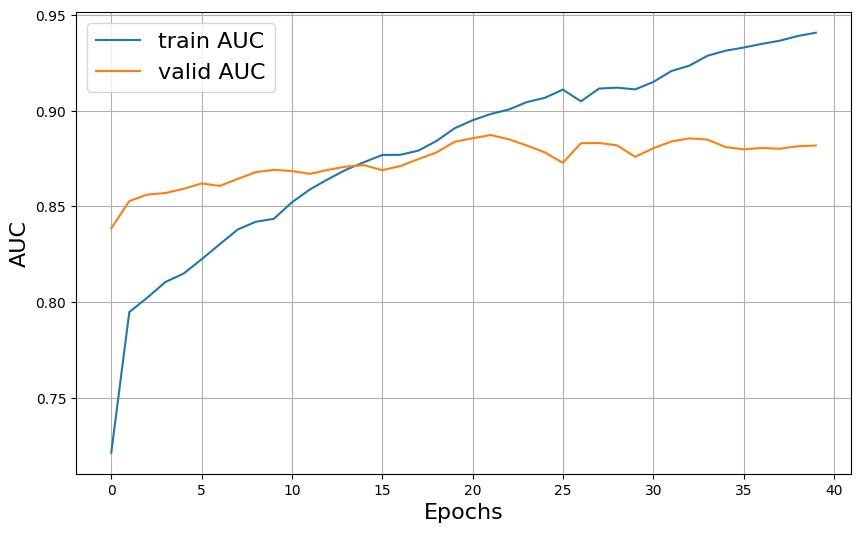

In [ ]:
train_dataset = MPNNDataset(x_train, y_train)
valid_dataset = MPNNDataset(x_valid, y_valid)

test_dataset = MPNNDataset(x_test, y_test)
history = mpnn.fit(
  train_dataset,
  validation_data=valid_dataset,
  epochs=40,
  verbose=2,
  class_weight={0: 2.0, 1: 0.5},
)

plt.figure(figsize=(10, 6))
plt.plot(history.history["AUC"], label="train AUC")
plt.plot(history.history["val_AUC"], label="valid AUC")
plt.xlabel("Epochs", fontsize=16)
plt.ylabel("AUC", fontsize=16)
plt.grid(True)
plt.legend(fontsize=16)

# задания:

## Задание № 1: Доработка сверточной графовой нейронной модели.
1. Доработать нашу модель: меняя параметры, типы аггрегации и комбинации, количество слоев свертки, значения для dropout.
2. Добиться, чтобы графовая модель стабильно выдавала лучший результат, чем референсная с такими же параметрами (dropout, batch_size).

## исходная модель

168052/168052 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
Citations shape: (5429, 2)
Papers shape: (2708, 1435)


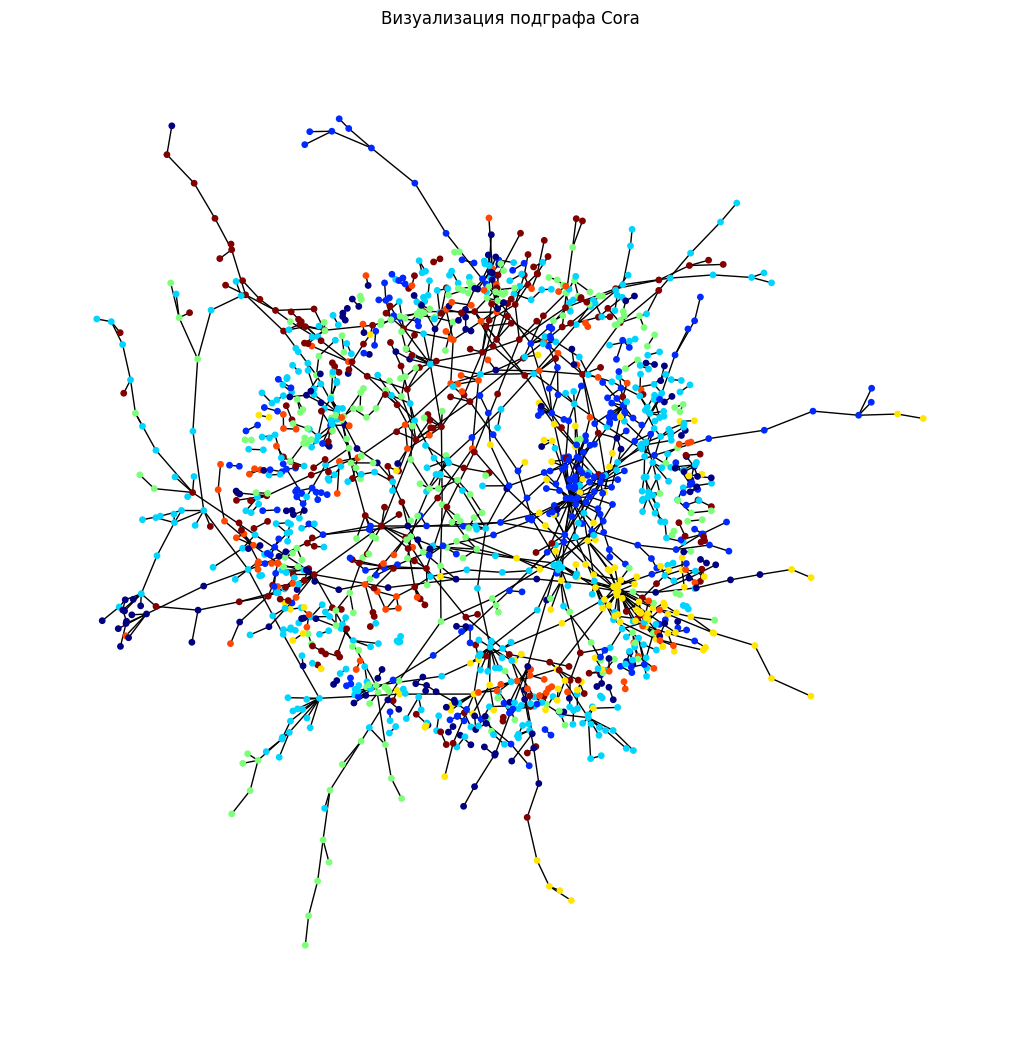

Train data shape: (1395, 1435)
Test data shape: (1313, 1435)
Edges shape: (2, 5429)
Nodes shape: (2708, 1433)


In [ ]:
zip_file = keras.utils.get_file(
    fname="cora.tgz",
    origin="https://linqs-data.soe.ucsc.edu/public/lbc/cora.tgz",
    extract=True,
)
data_dir = os.path.join(os.path.dirname(zip_file), "cora_extracted/cora")

citations = pd.read_csv(
    os.path.join(data_dir, "cora.cites"),
    sep="\t",
    header=None,
    names=["target", "source"],
)
print("Citations shape:", citations.shape)

column_names = ["paper_id"] + [f"term_{idx}" for idx in range(1433)] + ["subject"]
papers = pd.read_csv(
    os.path.join(data_dir, "cora.content"), sep="\t", header=None, names=column_names
)
print("Papers shape:", papers.shape)


paper_idx = {name: idx for idx, name in enumerate(sorted(papers["paper_id"].unique()))}

class_values = sorted(papers["subject"].unique())
class_idx = {name: id for id, name in enumerate(class_values)}

papers["paper_id"] = papers["paper_id"].apply(lambda name: paper_idx[name])
citations["source"] = citations["source"].apply(lambda name: paper_idx[name])
citations["target"] = citations["target"].apply(lambda name: paper_idx[name])
papers["subject"] = papers["subject"].apply(lambda value: class_idx[value])

feature_names = [f"term_{idx}" for idx in range(1433)]
num_classes = len(class_values)
num_features = len(feature_names)

plt.figure(figsize=(10, 10))
cora_graph = nx.from_pandas_edgelist(citations.sample(n=1500))
node_ids_in_graph = list(cora_graph.nodes)
papers_in_graph = papers[papers["paper_id"].isin(node_ids_in_graph)]
papers_in_graph = papers_in_graph.set_index("paper_id").loc[node_ids_in_graph]
subjects = papers_in_graph["subject"].tolist()
nx.draw_spring(cora_graph, node_size=15, node_color=subjects, cmap=plt.cm.jet)
plt.title("Визуализация подграфа Cora")
plt.show()


train_data, test_data = [], []
for _, group_data in papers.groupby("subject"):
    random_selection = np.random.rand(len(group_data.index)) <= 0.5
    train_data.append(group_data[random_selection])
    test_data.append(group_data[~random_selection])

train_data = pd.concat(train_data).sample(frac=1)
test_data = pd.concat(test_data).sample(frac=1)
print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

x_train = train_data["paper_id"].to_numpy()
y_train = train_data["subject"].to_numpy()
x_test = test_data["paper_id"].to_numpy()
y_test = test_data["subject"].to_numpy()

hidden_units = [32, 32]
learning_rate = 0.01
dropout_rate = 0.5
num_epochs = 300
batch_size = 256

def run_experiment(model, x_train, y_train, x_test, y_test):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")],
    )
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_acc", patience=50, restore_best_weights=True
    )
    history = model.fit(
        x=x_train,
        y=y_train,
        epochs=num_epochs,
        batch_size=batch_size,
        validation_data=(x_test, y_test),
        callbacks=[early_stopping],
        verbose=1
    )
    return history

def display_learning_curves(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    ax1.plot(history.history["loss"], label="train_loss")
    ax1.plot(history.history["val_loss"], label="val_loss")
    ax1.legend()
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax2.plot(history.history["acc"], label="train_acc")
    ax2.plot(history.history["val_acc"], label="val_acc")
    ax2.legend()
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Accuracy")
    plt.grid(True)
    plt.show()


edges = citations[["source", "target"]].to_numpy().T
edge_weights = tf.ones(shape=edges.shape[1])
node_features = tf.cast(
    papers.sort_values("paper_id")[feature_names].to_numpy(), dtype=tf.dtypes.float32
)

graph_info = (node_features, edges, edge_weights)
print("Edges shape:", edges.shape)
print("Nodes shape:", node_features.shape)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1433)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 64)             │       101,924 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,379 (399.92 KB)

 Trainable params: 99,385 (388.22 KB)

 Non-trainable params: 2,994 (11.70 KB)

Epoch 1/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step - acc: 0.1914 - loss: 2.2055 - val_acc: 0.4196 - val_loss: 1.8569
Epoch 2/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - acc: 0.3814 - loss: 1.6191 - val_acc: 0.4676 - val_loss: 1.7569
Epoch 3/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - acc: 0.4996 - loss: 1.3627 - val_acc: 0.5484 - val_loss: 1.6509
Epoch 4/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - acc: 0.6143 - loss: 1.1356 - val_acc: 0.5605 - val_loss: 1.5085
Epoch 5/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - acc: 0.6824 - loss: 0.9490 - val_acc: 0.5133 - val_loss: 1.3658
Epoch 6/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - acc: 0.7534 - loss: 0.7514 - val_acc: 0.5263 - val_loss: 1.2751
Epoch 7/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - acc: 0.7892 - loss: 0.6392 - val_acc: 0.5430 - val_loss: 1.2200
Epoch 8/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - acc: 0.8444 - loss: 0.5172 - val_acc: 0.5979 - val_loss: 1.1550
Epoch 9/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - acc: 0.8695 - loss: 

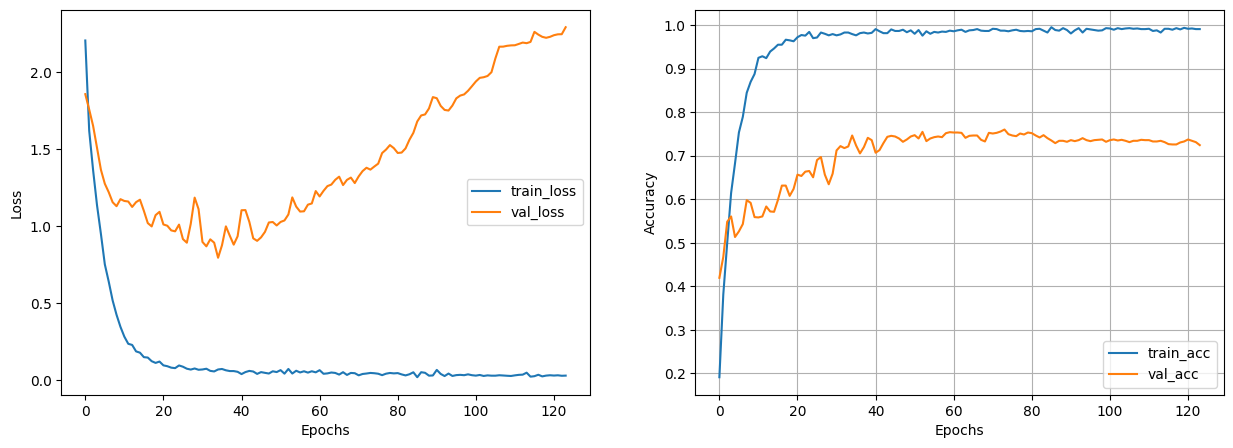

42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.7601 - loss: 1.3668
Baseline FFN Test Accuracy: 76.01%


In [ ]:
def create_ffn(hidden_units, dropout_rate, name=None):
    fnn_layers = []
    for units in hidden_units:
        fnn_layers.append(layers.BatchNormalization())
        fnn_layers.append(layers.Dense(units, activation=tf.nn.gelu))
        fnn_layers.append(layers.Dropout(dropout_rate))
    return keras.Sequential(fnn_layers, name=name)

def create_baseline_model(hidden_units, dropout_rate):
    inputs = layers.Input(shape=(num_features,))
    x = create_ffn(hidden_units, dropout_rate)(inputs)
    logits = layers.Dense(units=num_classes)(x)
    return keras.Model(inputs=inputs, outputs=logits)

ffn_hidden_units = [64, 64]
ffn_dropout_rate = 0.5
learning_rate = 0.005
batch_size = 256

baseline_model = create_baseline_model(ffn_hidden_units, ffn_dropout_rate)
baseline_model.summary()


x_train_features = train_data[feature_names].to_numpy()
x_test_features = test_data[feature_names].to_numpy()

history_baseline = run_experiment(baseline_model, x_train_features, y_train, x_test_features, y_test)

display_learning_curves(history_baseline)
_, test_accuracy = baseline_model.evaluate(x_test_features, y_test, verbose=1)
print(f"Baseline FFN Test Accuracy: {test_accuracy*100:.2f}%")

## модернизированная модель

In [ ]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

zip_file = keras.utils.get_file(
    fname="cora.tgz",
    origin="https://linqs-data.soe.ucsc.edu/public/lbc/cora.tgz",
    extract=True,
)
data_dir = os.path.join(os.path.dirname(zip_file), "cora_extracted/cora")

papers = pd.read_csv(os.path.join(data_dir, "cora.content"), sep="\t", header=None)
citations = pd.read_csv(os.path.join(data_dir, "cora.cites"), sep="\t", header=None, names=["target", "source"])

papers.columns = ["paper_id"] + [f"term_{idx}" for idx in range(1433)] + ["subject"]
papers.sort_values("paper_id", inplace=True)
papers.reset_index(drop=True, inplace=True)

paper_idx = {name: idx for idx, name in enumerate(papers["paper_id"])}
class_idx = {name: id for id, name in enumerate(sorted(papers["subject"].unique()))}

node_features = papers.iloc[:, 1:-1].to_numpy().astype("float32")
node_features = tf.nn.l2_normalize(node_features, axis=-1)
labels = papers["subject"].map(class_idx).to_numpy()

adj = [[] for _ in range(len(papers))]
for src, tgt in zip(citations["source"], citations["target"]):
    if src in paper_idx and tgt in paper_idx:
        s, t = paper_idx[src], paper_idx[tgt]
        adj[t].append(s)
        adj[s].append(t)

MAX_NEIGHBORS = 15
neighbor_array = np.zeros((len(papers), MAX_NEIGHBORS), dtype="int32")

for i in range(len(papers)):
    neighbors = adj[i]
    if len(neighbors) == 0:
        neighbor_array[i] = np.full(MAX_NEIGHBORS, i)
    else:
        neighbors_with_self = neighbors + [i]
        neighbor_array[i] = np.random.choice(neighbors_with_self, MAX_NEIGHBORS, replace=True)

indices = np.arange(len(papers))
np.random.seed(42)
np.random.shuffle(indices)
train_indices = indices[:len(indices)//2]
test_indices = indices[len(indices)//2:]



class GraphSageLayer(layers.Layer):
    def __init__(self, units, dropout_rate=0.5, **kwargs):
        super().__init__(**kwargs)
        self.update_fn = layers.Dense(units, activation="relu")
        self.dropout = layers.Dropout(dropout_rate)
        self.bn = layers.BatchNormalization()

    def call(self, inputs):
        node_reps, neighbor_reps = inputs
        aggregated = tf.reduce_mean(neighbor_reps, axis=1)
        combined = tf.concat([node_reps, aggregated], axis=-1)
        x = self.update_fn(combined)
        x = self.dropout(x)
        return self.bn(x)

class GNNModel(tf.keras.Model):
    def __init__(self, num_classes, hidden_units=128, dropout_rate=0.5):
        super().__init__()
        self.node_features = tf.constant(node_features)
        self.neighbor_tensor = tf.constant(neighbor_array)
        self.input_proj = layers.Dense(hidden_units, activation="relu")

        self.layer1 = GraphSageLayer(hidden_units, dropout_rate)
        self.layer2 = GraphSageLayer(hidden_units, dropout_rate)
        self.logits = layers.Dense(num_classes)

    def call(self, inputs):
        batch_idx = inputs
        h_target = self.input_proj(tf.gather(self.node_features, batch_idx))
        neighbor_idx = tf.gather(self.neighbor_tensor, batch_idx)
        h_neighbors = self.input_proj(tf.gather(self.node_features, neighbor_idx))

        h1 = self.layer1((h_target, h_neighbors))
        h2 = self.layer2((h1, h_neighbors))
        return self.logits(h2)

model = GNNModel(num_classes=len(class_idx))
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["acc"]
)

history = model.fit(
    train_indices, labels[train_indices],
    batch_size=128,
    epochs=100,
    validation_split=0.15,
    callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
    verbose=1
)

def display_learning_curves(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    ax1.plot(history.history["loss"], label="Train Loss", color='blue')
    ax1.plot(history.history["val_loss"], label="Val Loss", color='orange')
    ax1.set_title("Learning Curve: Loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)

    ax2.plot(history.history["acc"], label="Train Acc", color='blue')
    ax2.plot(history.history["val_acc"], label="Val Acc", color='orange')
    ax2.axhline(y=0.72, color='red', linestyle='--', label="Reference (72%)")
    ax2.set_title("Learning Curve: Accuracy")
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True)

    plt.show()

display_learning_curves(history)

test_loss, test_acc = model.evaluate(test_indices, labels[test_indices], verbose=0)
print(f"\nFinal Test Accuracy: {test_acc*100:.2f}%")

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 266ms/step - acc: 0.2887 - loss: 1.8836 - val_acc: 0.2794 - val_loss: 1.8289
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 157ms/step - acc: 0.3087 - loss: 1.7348 - val_acc: 0.2794 - val_loss: 1.7031
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - acc: 0.3904 - loss: 1.5000 - val_acc: 0.4706 - val_loss: 1.4242
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - acc: 0.6687 - loss: 1.1263 - val_acc: 0.6373 - val_loss: 1.0581
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - acc: 0.7870 - loss: 0.7406 - val_acc: 0.7598 - val_loss: 0.7566
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - acc: 0.8687 - loss: 0.4683 - val_acc: 0.8186 - val_loss: 0.5587
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - acc: 0.9322 - loss: 0.2923 - val_acc: 0.8235 - val_loss: 0.4822
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - acc: 0.9652 - loss: 0.1697 - val_acc: 0.8480 - val_loss: 0.4179
Epoch 9/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - acc: 0.9852

## Задание № 2: Доработка графовой модели для молекулярных графов.
1. Попробовать обучать модель на графических ускорителях. Сравнить
время обучения графовой модели на ускорителях и на процессорах.
2. Доработать нашу модель: меняя параметры, добавляя слои dropout и
меняя их вероятности.
3. Добиться, чтобы графовая модель стабильно выдавала результат на те
стовых и валидатационных данных выше 95 процентов

п 1: обучение на процессоре

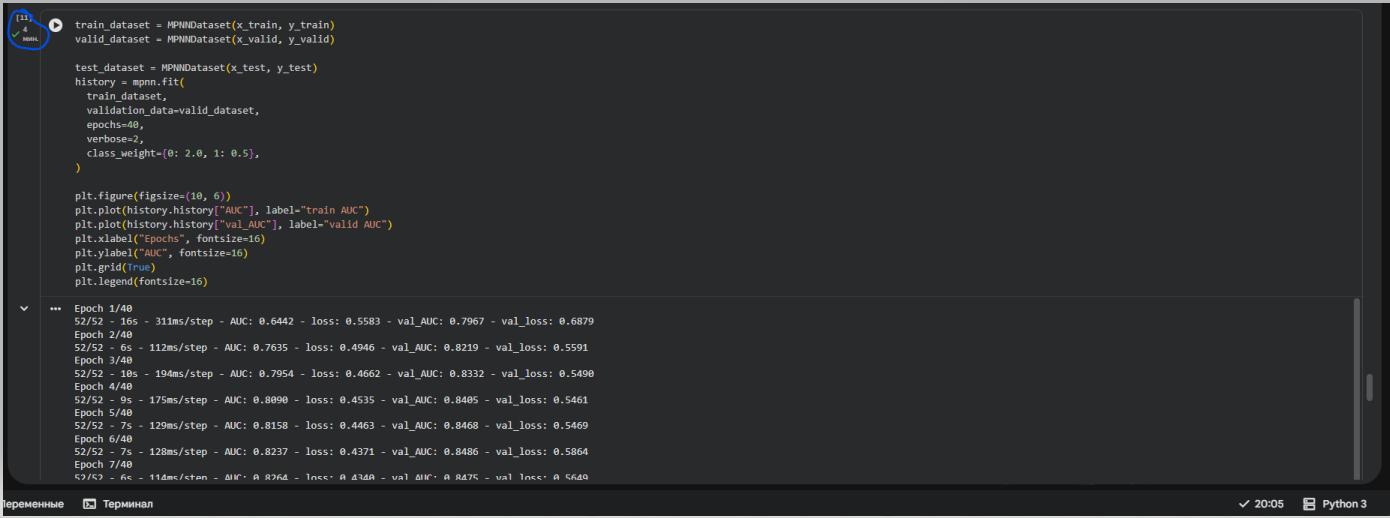

обучение на графическом процессоре

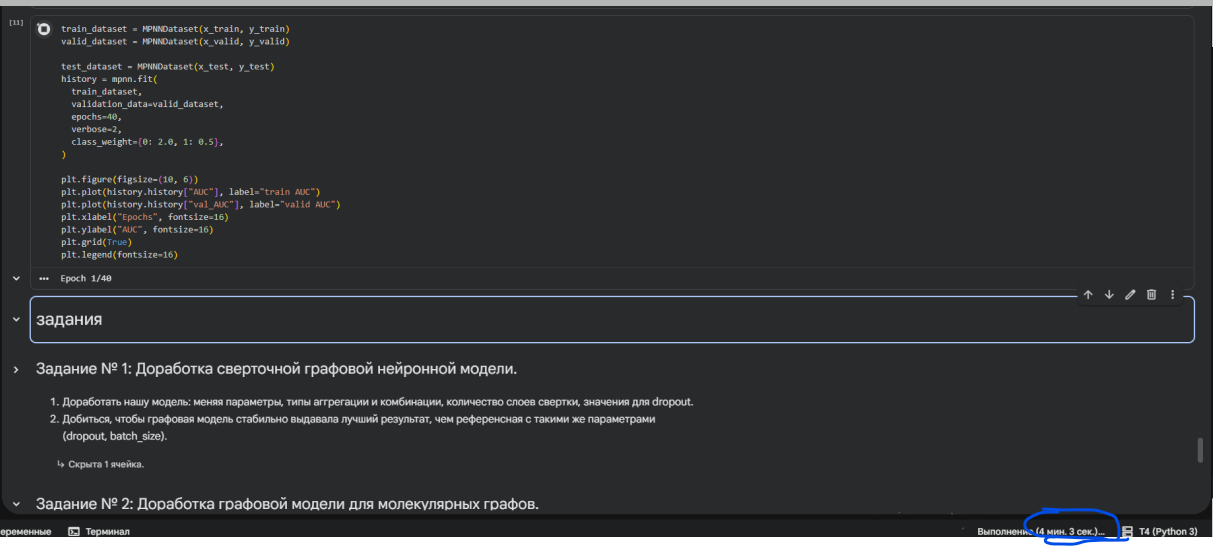

Train size: 1742, Valid size: 205, Test size: 103


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ atom_features       │ (None, 29)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bond_features       │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pair_indices        │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ message_passing_1   │ (None, 64)        │     57,856 │ atom_features[0]… │
│ (MessagePassing)    │                   │            │ bond_features[0]… │
│                     │                   │            │ pair_indices[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ molecule_indicator  │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, 64)        │    166,016 │ message_passing_… │
│ (TransformerEncode… │                   │            │ molecule_indicat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 256)       │     16,640 │ transformer_enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_8[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 256)       │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 128)       │     32,896 │ dropout_15[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_9[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 128)       │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 64)        │      8,256 │ dropout_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_10[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_17          │ (None, 64)        │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 1)         │         65 │ dropout_17[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 283,521 (1.08 MB)

 Trainable params: 282,625 (1.08 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/100
55/55 - 59s - 1s/step - AUC: 0.6840 - loss: 0.6185 - val_AUC: 0.6951 - val_loss: 0.6610
Epoch 2/100
55/55 - 48s - 876ms/step - AUC: 0.7653 - loss: 0.5273 - val_AUC: 0.8381 - val_loss: 0.5403
Epoch 3/100
55/55 - 48s - 869ms/step - AUC: 0.8122 - loss: 0.4855 - val_AUC: 0.8343 - val_loss: 0.5541
Epoch 4/100
55/55 - 47s - 847ms/step - AUC: 0.8291 - loss: 0.4699 - val_AUC: 0.8637 - val_loss: 0.4859
Epoch 5/100
55/55 - 47s - 862ms/step - AUC: 0.8205 - loss: 0.4739 - val_AUC: 0.8899 - val_loss: 0.4705
Epoch 6/100
55/55 - 46s - 842ms/step - AUC: 0.8333 - loss: 0.4573 - val_AUC: 0.8315 - val_loss: 0.8053
Epoch 7/100
55/55 - 48s - 871ms/step - AUC: 0.8419 - loss: 0.4524 - val_AUC: 0.8235 - val_loss: 0.4217
Epoch 8/100
55/55 - 48s - 873ms/step - AUC: 0.8461 - loss: 0.4426 - val_AUC: 0.8940 - val_loss: 0.5756
Epoch 9/100
55/55 - 48s - 881ms/step - AUC: 0.8573 - loss: 0.4301 - val_AUC: 0.8891 - val_loss: 0.5915
Epoch 10/100
55/55 - 49s - 888ms/step - AUC: 0.8805 - loss: 0.4025 - val_AUC

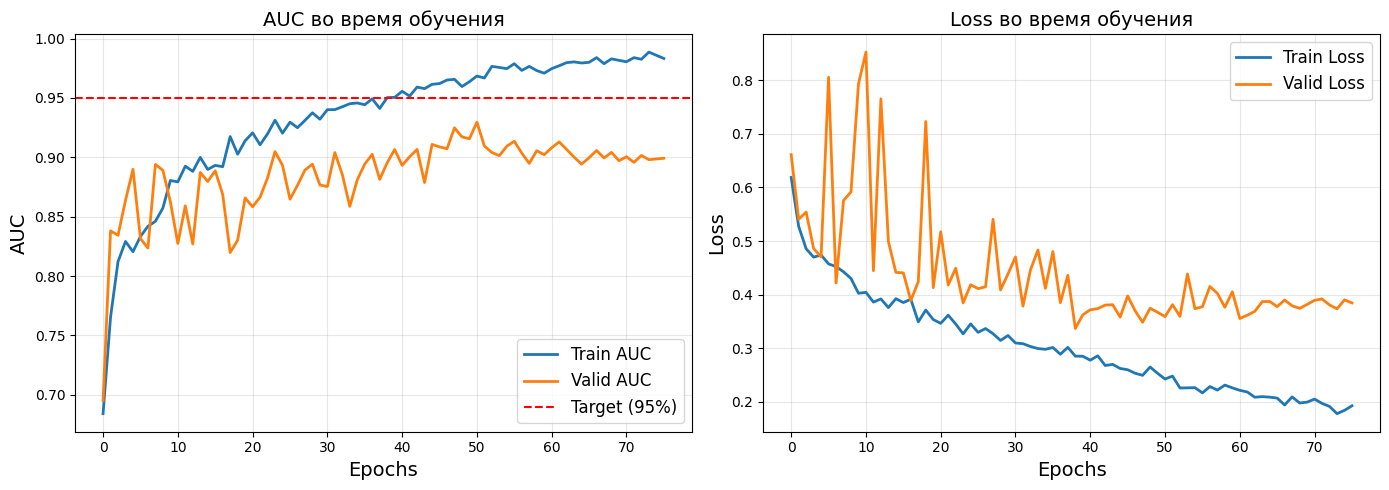


ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ:
Лучший Train AUC: 0.9887
Лучший Valid AUC: 0.9297
Test AUC: 0.8625


In [ ]:
import os

# Temporary suppress tf logs
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from rdkit import Chem
from rdkit import RDLogger

# Temporary suppress warnings and RDKit logs
warnings.filterwarnings("ignore")
RDLogger.DisableLog("rdApp.*")
np.random.seed(42)
tf.random.set_seed(42)

csv_path = keras.utils.get_file("BBBP.csv", "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/BBBP.csv")
df = pd.read_csv(csv_path, usecols=[1, 2, 3])

class Featurizer:
    def __init__(self, allowable_sets):
        self.dim = 0
        self.features_mapping = {}
        for k, s in allowable_sets.items():
            s = sorted(list(s))
            self.features_mapping[k] = dict(zip(s, range(self.dim, len(s) + self.dim)))
            self.dim += len(s)

    def encode(self, inputs):
        output = np.zeros((self.dim,))
        for name_feature, feature_mapping in self.features_mapping.items():
            feature = getattr(self, name_feature)(inputs)
            if feature not in feature_mapping:
                continue
            output[feature_mapping[feature]] = 1.0
        return output


class AtomFeaturizer(Featurizer):
    def __init__(self, allowable_sets):
        super().__init__(allowable_sets)

    def symbol(self, atom):
        return atom.GetSymbol()

    def n_valence(self, atom):
        return atom.GetTotalValence()

    def n_hydrogens(self, atom):
        return atom.GetTotalNumHs()

    def hybridization(self, atom):
        return atom.GetHybridization().name.lower()


class BondFeaturizer(Featurizer):
    def __init__(self, allowable_sets):
        super().__init__(allowable_sets)
        self.dim += 1

    def encode(self, bond):
        output = np.zeros((self.dim,))
        if bond is None:
            output[-1] = 1.0
            return output
        output = super().encode(bond)
        return output

    def bond_type(self, bond):
        return bond.GetBondType().name.lower()

    def conjugated(self, bond):
        return bond.GetIsConjugated()


atom_featurizer = AtomFeaturizer(
    allowable_sets={
        "symbol": {"B", "Br", "C", "Ca", "Cl", "F", "H", "I", "N", "Na", "O", "P", "S"},
        "n_valence": {0, 1, 2, 3, 4, 5, 6},
        "n_hydrogens": {0, 1, 2, 3, 4},
        "hybridization": {"s", "sp", "sp2", "sp3"},
    }
)

bond_featurizer = BondFeaturizer(
    allowable_sets={
        "bond_type": {"single", "double", "triple", "aromatic"},
        "conjugated": {True, False},
    }
)


def molecule_from_smiles(smiles):
    molecule = Chem.MolFromSmiles(smiles, sanitize=False)
    flag = Chem.SanitizeMol(molecule, catchErrors=True)
    if flag != Chem.SanitizeFlags.SANITIZE_NONE:
        Chem.SanitizeMol(molecule, sanitizeOps=Chem.SanitizeFlags.SANITIZE_ALL ^ flag)
    Chem.AssignStereochemistry(molecule, cleanIt=True, force=True)
    return molecule


def graph_from_molecule(molecule):
    atom_features = []
    bond_features = []
    pair_indices = []
    for atom in molecule.GetAtoms():
        atom_features.append(atom_featurizer.encode(atom))
        pair_indices.append([atom.GetIdx(), atom.GetIdx()])
        bond_features.append(bond_featurizer.encode(None))
        for neighbor in atom.GetNeighbors():
            bond = molecule.GetBondBetweenAtoms(atom.GetIdx(), neighbor.GetIdx())
            pair_indices.append([atom.GetIdx(), neighbor.GetIdx()])
            bond_features.append(bond_featurizer.encode(bond))
    return np.array(atom_features), np.array(bond_features), np.array(pair_indices)


def graphs_from_smiles(smiles_list):
    atom_features_list = []
    bond_features_list = []
    pair_indices_list = []
    for smiles in smiles_list:
        molecule = molecule_from_smiles(smiles)
        atom_features, bond_features, pair_indices = graph_from_molecule(molecule)
        atom_features_list.append(atom_features)
        bond_features_list.append(bond_features)
        pair_indices_list.append(pair_indices)
    return (
        tf.ragged.constant(atom_features_list, dtype=tf.float32),
        tf.ragged.constant(bond_features_list, dtype=tf.float32),
        tf.ragged.constant(pair_indices_list, dtype=tf.int64),
    )


# Разбиение данных
permuted_indices = np.random.permutation(np.arange(df.shape[0]))

train_index = permuted_indices[: int(df.shape[0] * 0.85)]
x_train = graphs_from_smiles(df.iloc[train_index].smiles)
y_train = df.iloc[train_index].p_np

valid_index = permuted_indices[int(df.shape[0] * 0.85): int(df.shape[0] * 0.95)]
x_valid = graphs_from_smiles(df.iloc[valid_index].smiles)
y_valid = df.iloc[valid_index].p_np

test_index = permuted_indices[int(df.shape[0] * 0.95):]
x_test = graphs_from_smiles(df.iloc[test_index].smiles)
y_test = df.iloc[test_index].p_np

print(f"Train size: {len(y_train)}, Valid size: {len(y_valid)}, Test size: {len(y_test)}")


def prepare_batch(x_batch, y_batch):
    atom_features, bond_features, pair_indices = x_batch
    num_atoms = atom_features.row_lengths()
    num_bonds = bond_features.row_lengths()
    molecule_indices = tf.range(len(num_atoms))
    molecule_indicator = tf.repeat(molecule_indices, num_atoms)
    gather_indices = tf.repeat(molecule_indices[:-1], num_bonds[1:])
    increment = tf.cumsum(num_atoms[:-1])
    increment = tf.pad(tf.gather(increment, gather_indices), [(num_bonds[0], 0)])
    pair_indices = pair_indices.merge_dims(outer_axis=0, inner_axis=1).to_tensor()
    pair_indices = pair_indices + increment[:, tf.newaxis]
    atom_features = atom_features.merge_dims(outer_axis=0, inner_axis=1).to_tensor()
    bond_features = bond_features.merge_dims(outer_axis=0, inner_axis=1).to_tensor()
    return (atom_features, bond_features, pair_indices, molecule_indicator), y_batch


def MPNNDataset(X, y, batch_size=32, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((X, (y)))
    if shuffle:
        dataset = dataset.shuffle(1024)
    return dataset.batch(batch_size).map(prepare_batch, -1).prefetch(-1)


class EdgeNetwork(layers.Layer):
    def __init__(self, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.dropout_rate = dropout_rate

    def build(self, input_shape):
        self.atom_dim = input_shape[0][-1]
        self.bond_dim = input_shape[1][-1]
        self.kernel = self.add_weight(
            shape=(self.bond_dim, self.atom_dim * self.atom_dim),
            initializer="glorot_uniform",
            name="kernel",
        )
        self.bias = self.add_weight(
            shape=(self.atom_dim * self.atom_dim,),
            initializer="zeros",
            name="bias",
        )
        self.dropout = layers.Dropout(self.dropout_rate)
        self.built = True

    def call(self, inputs, training=False):
        atom_features, bond_features, pair_indices = inputs
        bond_features = tf.matmul(bond_features, self.kernel) + self.bias
        bond_features = self.dropout(bond_features, training=training)
        bond_features = tf.reshape(bond_features, (-1, self.atom_dim, self.atom_dim))
        atom_features_neighbors = tf.gather(atom_features, pair_indices[:, 1])
        atom_features_neighbors = tf.expand_dims(atom_features_neighbors, axis=-1)
        transformed_features = tf.matmul(bond_features, atom_features_neighbors)
        transformed_features = tf.squeeze(transformed_features, axis=-1)
        aggregated_features = tf.math.unsorted_segment_sum(
            transformed_features,
            pair_indices[:, 0],
            num_segments=tf.shape(atom_features)[0],
        )
        return aggregated_features


class MessagePassing(layers.Layer):
    def __init__(self, units, steps=4, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.steps = steps
        self.dropout_rate = dropout_rate

    def build(self, input_shape):
        self.atom_dim = input_shape[0][-1]
        self.message_step = EdgeNetwork(dropout_rate=self.dropout_rate)
        self.pad_length = max(0, self.units - self.atom_dim)
        self.update_step = layers.GRUCell(self.atom_dim + self.pad_length)
        self.dropout = layers.Dropout(self.dropout_rate)
        self.layer_norm = layers.LayerNormalization()
        self.built = True

    def call(self, inputs, training=False):
        atom_features, bond_features, pair_indices = inputs
        atom_features_updated = tf.pad(atom_features, [(0, 0), (0, self.pad_length)])

        for i in range(self.steps):
            atom_features_aggregated = self.message_step(
                [atom_features_updated, bond_features, pair_indices], training=training
            )
            atom_features_aggregated = self.dropout(atom_features_aggregated, training=training)
            atom_features_updated, _ = self.update_step(
                atom_features_aggregated, atom_features_updated
            )
            atom_features_updated = self.layer_norm(atom_features_updated)

        return atom_features_updated


class PartitionPadding(layers.Layer):
    def call(self, inputs):
        atom_features, molecule_indicator = inputs
        num_molecules = tf.reduce_max(molecule_indicator) + 1
        atom_counts = tf.math.unsorted_segment_sum(
            tf.ones_like(molecule_indicator, dtype=tf.int32),
            molecule_indicator,
            num_molecules
        )
        sorted_indices = tf.argsort(molecule_indicator)
        sorted_atom_features = tf.gather(atom_features, sorted_indices)
        atom_features_ragged = tf.RaggedTensor.from_row_lengths(
            sorted_atom_features,
            tf.cast(atom_counts, tf.int64)
        )
        return atom_features_ragged.to_tensor()


class TransformerEncoderReadout(layers.Layer):
    def __init__(self, num_heads=8, embed_dim=64, dense_dim=512, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.partition_padding = PartitionPadding()
        self.attention = layers.MultiHeadAttention(num_heads, embed_dim, dropout=dropout_rate)
        self.dense_proj = keras.Sequential([
            layers.Dense(dense_dim, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(embed_dim),
        ])
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()
        self.dropout_1 = layers.Dropout(dropout_rate)
        self.dropout_2 = layers.Dropout(dropout_rate)
        self.average_pooling = layers.GlobalAveragePooling1D()

    def call(self, inputs, training=False):
        x = self.partition_padding(inputs)
        padding_mask = tf.reduce_any(tf.not_equal(x, 0.0), axis=-1)
        padding_mask = padding_mask[:, tf.newaxis, tf.newaxis, :]
        attention_output = self.attention(x, x, attention_mask=padding_mask, training=training)
        attention_output = self.dropout_1(attention_output, training=training)
        proj_input = self.layernorm_1(x + attention_output)
        proj_output = self.dense_proj(proj_input, training=training)
        proj_output = self.dropout_2(proj_output, training=training)
        proj_output = self.layernorm_2(proj_input + proj_output)
        return self.average_pooling(proj_output)


def MPNNModel(
    atom_dim,
    bond_dim,
    message_units=64,
    message_steps=6,
    num_attention_heads=8,
    dense_units=256,
    dropout_rate=0.2,
):
    atom_features = layers.Input((atom_dim,), dtype="float32", name="atom_features")
    bond_features = layers.Input((bond_dim,), dtype="float32", name="bond_features")
    pair_indices = layers.Input((2,), dtype="int32", name="pair_indices")
    molecule_indicator = layers.Input((), dtype="int32", name="molecule_indicator")

    x = MessagePassing(message_units, message_steps, dropout_rate=dropout_rate)(
        [atom_features, bond_features, pair_indices]
    )

    x = TransformerEncoderReadout(
        num_attention_heads, message_units, dense_units, dropout_rate=dropout_rate
    )([x, molecule_indicator])

    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(dense_units // 2, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(dense_units // 4, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate / 2)(x)

    x = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(
        inputs=[atom_features, bond_features, pair_indices, molecule_indicator],
        outputs=[x],
    )
    return model


BATCH_SIZE = 32

mpnn = MPNNModel(
    atom_dim=x_train[0][0][0].shape[0],
    bond_dim=x_train[1][0][0].shape[0],
    message_units=64,
    message_steps=6,
    num_attention_heads=8,
    dense_units=256,
    dropout_rate=0.2,
)

# используем CosineDecay (без рестартов) для стабильности
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=5e-4,
    decay_steps=100 * 55,  # epochs * steps_per_epoch
    alpha=1e-6
)

mpnn.compile(
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    optimizer=keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-5),
    metrics=[keras.metrics.AUC(name="AUC")],
)

mpnn.summary()

train_dataset = MPNNDataset(x_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
valid_dataset = MPNNDataset(x_valid, y_valid, batch_size=BATCH_SIZE)
test_dataset = MPNNDataset(x_test, y_test, batch_size=BATCH_SIZE)

# убрал ReduceLROnPlateau, оставил только EarlyStopping
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_AUC",
        patience=25,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
]

history = mpnn.fit(
    train_dataset,
    validation_data=valid_dataset,
    epochs=100,
    verbose=2,
    class_weight={0: 2.0, 1: 0.5},
    callbacks=callbacks,
)

print("\n" + "="*50)
print("Оценка на тестовых данных:")
test_results = mpnn.evaluate(test_dataset, verbose=1)
print(f"Test Loss: {test_results[0]:.4f}")
print(f"Test AUC: {test_results[1]:.4f}")

print("\nОценка на валидационных данных:")
valid_results = mpnn.evaluate(valid_dataset, verbose=1)
print(f"Valid Loss: {valid_results[0]:.4f}")
print(f"Valid AUC: {valid_results[1]:.4f}")
print("="*50)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["AUC"], label="Train AUC", linewidth=2)
axes[0].plot(history.history["val_AUC"], label="Valid AUC", linewidth=2)
axes[0].axhline(y=0.95, color='r', linestyle='--', label='Target (95%)')
axes[0].set_xlabel("Epochs", fontsize=14)
axes[0].set_ylabel("AUC", fontsize=14)
axes[0].set_title("AUC во время обучения", fontsize=14)
axes[0].legend(fontsize=12)
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history["loss"], label="Train Loss", linewidth=2)
axes[1].plot(history.history["val_loss"], label="Valid Loss", linewidth=2)
axes[1].set_xlabel("Epochs", fontsize=14)
axes[1].set_ylabel("Loss", fontsize=14)
axes[1].set_title("Loss во время обучения", fontsize=14)
axes[1].legend(fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_history.png", dpi=150)
plt.show()

print("\n" + "="*50)
print("ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ:")
print(f"Лучший Train AUC: {max(history.history['AUC']):.4f}")
print(f"Лучший Valid AUC: {max(history.history['val_AUC']):.4f}")
print(f"Test AUC: {test_results[1]:.4f}")
print("="*50)